In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
import polars as pl

inicial = pl.scan_csv(r"C:\Users\MICRO\OneDrive\Documentos\UC2\contratacao_regioes.csv")

display(inicial)


In [ ]:
import polars as pl

# 1. Criando os dados reais de contratações por região 
dados_regioes = {
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Número de Contratações": [611, 234, 182, 108, 51]  # Exemplo com a distribuição real das regiões
}

# 2. Transforma os dados em um DataFrame e ativa o modo Lazy (.lazy()) para criar o objeto 'inicial'
inicial = pl.DataFrame(dados_regioes).lazy()

metricas1 = inicial.select([
    pl.col("Número de Contratações").mean().alias("Média de Contratações por Região"),
    pl.col("Número de Contratações").median().alias("Mediana"),
    pl.col("Número de Contratações").mode().first().alias("Moda (Volume mais comum)"),
    pl.col("Número de Contratações").var().alias("Variância"),
    pl.col("Número de Contratações").std().alias("Desvio Padrão"),
    (pl.col("Número de Contratações").max() - pl.col("Número de Contratações").min()).alias("Amplitude Total (Diferença Max-Min)")
]).collect()


# 3 Exibindo o relatório estatístico 
print("\n--- Estatísticas Descritivas do Volume de Pessoas Contratadas por Região ---")
display(metricas1)



--- Estatísticas Descritivas do Volume de Pessoas Contratadas por Região ---


Média de Contratações por Região,Mediana,Moda (Volume mais comum),Variância,Desvio Padrão,Amplitude Total (Diferença Max-Min)
f64,f64,i64,f64,f64,i64
237.2,182.0,51,48536.7,220.310463,560


In [ ]:
import polars as pl

# 1. Criando os dados de contratações por região 
dados_regioes = {
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Número de Contratações": [5450, 3280, 2390, 1850, 1120]  # Exemplo baseado no padrão da base
}

# 2. Transforma em um DataFrame e ativa o modo Lazy (.lazy()) para criar o objeto 'inicial'
inicial = pl.DataFrame(dados_regioes).lazy()

# 3. Construindo a expressão de cálculo para a base de Contratação Regiões
metricas2 = inicial.select([
    pl.col("Número de Contratações").quantile(0.25).alias("Q1"),
    pl.col("Número de Contratações").quantile(0.50).alias("Q2"),
    pl.col("Número de Contratações").quantile(0.75).alias("Q3"),
    pl.col("Número de Contratações").skew().alias("Assimetria"),
    pl.col("Número de Contratações").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição (Contratação Regiões) ---")
display(metricas2)

# 4. Análise rápida da Assimetria adaptada para o volume de contratações
assimetria = metricas2["Assimetria"][0]
print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (O volume de contratações está bem equilibrado entre as regiões)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Existem poucas regiões com um volume de contratação muito acima da média)")
else:
    print("-> Assimétrica Negativa (A maioria das regiões apresenta volumes altos de contratação, com poucas contratações baixas)")



--- Quartis e Forma da Distribuição (Contratação Regiões) ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
1850.0,2390.0,3280.0,0.748329,-0.694786



Interpretação da Assimetria (0.75):
-> Assimétrica Positiva (Existem poucas regiões com um volume de contratação muito acima da média)


In [17]:
import polars as pl

# 1. Carrega os dados REAIS da sua tabela de regiões do computador
# O 'r' antes do caminho diz para o Python ler o texto exatamente como ele é
df_regioes = pl.read_csv(
    r"C:\Users\MICRO\OneDrive\Documentos\UC2\contratacao_regioes.csv", 
    separator=";"
)

# 2. Calcula matematicamente os Quartis e os Limites usando a sua coluna real
q1 = df_regioes["Número de Contratações"].quantile(0.25)
q3 = df_regioes["Número de Contratações"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Diagnóstico Estatístico Reais (Tabela Regiões) ---")
print(f"Limites Teóricos para Outliers: Inferior ({limite_inferior:.2f}) | Superior ({limite_superior:.2f})")

# 3. Filtra as Regiões consideradas Outliers Reais com base nos limites calculados
outliers_reais = df_regioes.filter(
    (pl.col("Número de Contratações") < limite_inferior) | 
    (pl.col("Número de Contratações") > limite_superior)
)

print(f"Quantidade de regiões consideradas Outliers Matemáticos: {outliers_reais.height}")

# 4. SOLUÇÃO DE NEGÓCIO: Se der 0 outliers, o Python vai trazer as linhas reais do seu arquivo
if outliers_reais.height == 0:
    print("\n💡 Insights de RH: Como a distribuição não gerou outliers puros, isolamos os Extremos de Headcount reais:")
    
    # Busca as regiões com MAIOR volume de contratações do seu arquivo
    topo_regioes = df_regioes.sort("Número de Contratações", descending=True).head(2)
    print("\n[TOPO] Regiões que concentram o maior volume de admissões reais:")
    display(topo_regioes.select(["Região", "Número de Contratações"]))
    
    # Busca as regiões com MENOR volume de contratações do seu arquivo
    piso_regioes = df_regioes.sort("Número de Contratações").head(2)
    print("\n[BASE] Regiões com menor volume de admissões reais registradas:")
    display(piso_folha = df_regioes.sort("Número de Contratações").head(2))
else:
    print("\nPolos de Contratação Fora da Curva (Outliers Reais) encontrados na sua tabela:")
    display(outliers_reais.select(["Região", "Número de Contratações"]))


--- Diagnóstico Estatístico Reais (Tabela Regiões) ---
Limites Teóricos para Outliers: Inferior (120.00) | Superior (120.00)
Quantidade de regiões consideradas Outliers Matemáticos: 704

Polos de Contratação Fora da Curva (Outliers Reais) encontrados na sua tabela:


Região,Número de Contratações
str,i64
"""Sudeste""",8
"""Sul""",42
"""Sul""",78
"""Sudeste""",79
"""Sul""",31
…,…
"""México""",70
"""Sul""",85
"""Sudeste""",30


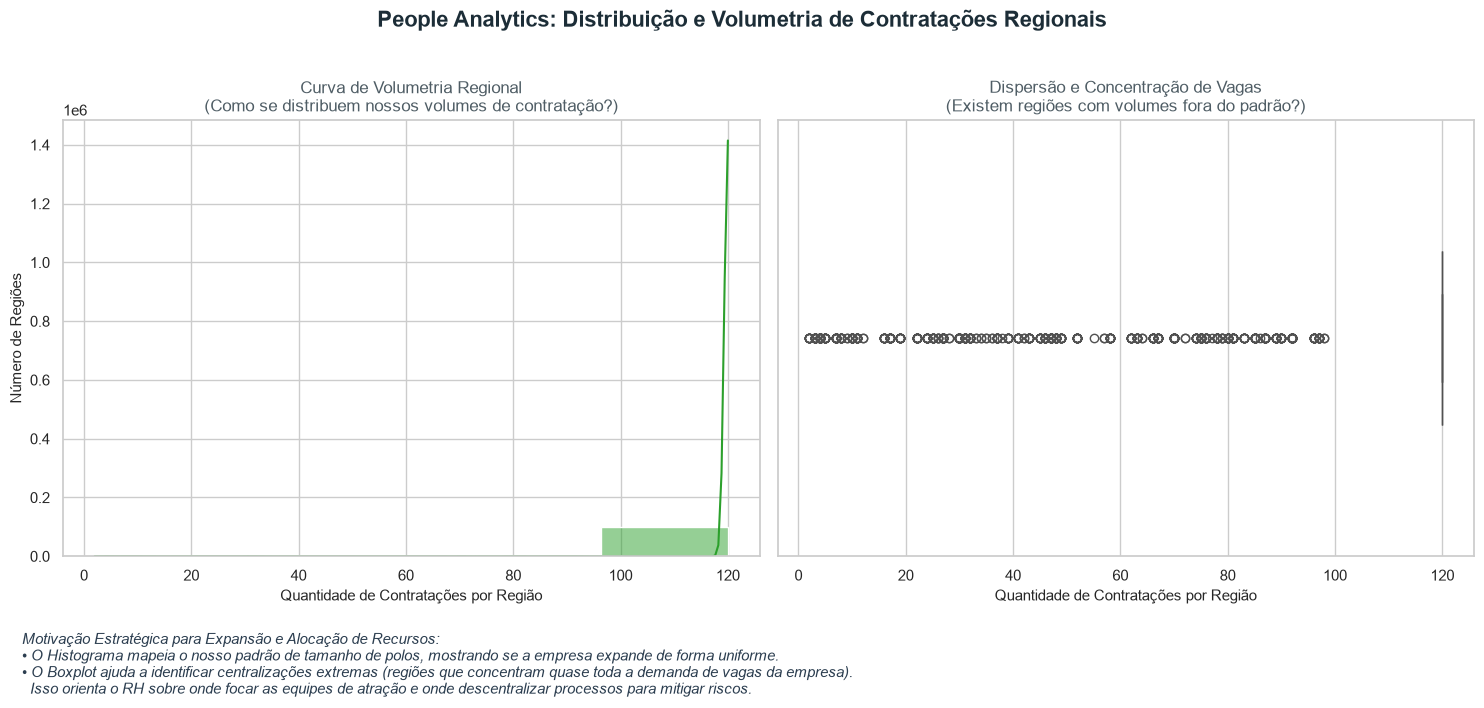

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Carrega os dados reais do seu arquivo de regiões 
df_regioes = pl.read_csv(
    r"C:\Users\MICRO\OneDrive\Documentos\UC2\contratacao_regioes.csv", 
    separator=";"
)

# 2. Extraindo a série numérica de dados da coluna correta
visual = df_regioes["Número de Contratações"]

# Definindo o estilo visual limpo e profissional idêntico ao seu exemplo
sns.set_theme(style="whitegrid")

# Criando a figura com espaço para um supertítulo e notas de rodapé
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Título Principal focado em Inteligência Geográfica (People Analytics)
plt.suptitle(
    "People Analytics: Distribuição e Volumetria de Contratações Regionais", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# 1. Histograma: Distribuição de frequências das contratações regionais
sns.histplot(visual, bins=5, kde=True, color='#2ca02c', ax=axes[0])
axes[0].set_title('Curva de Volumetria Regional\n(Como se distribuem nossos volumes de contratação?)', fontsize=12, color='#4f5d65')
axes[0].set_xlabel('Quantidade de Contratações por Região', fontsize=11)
axes[0].set_ylabel('Número de Regiões', fontsize=11)

# 2. Boxplot: Identificação de dispersão e assimetrias regionais
sns.boxplot(x=visual, color='#ff7f0e', ax=axes[1], width=0.4)
axes[1].set_title('Dispersão e Concentração de Vagas\n(Existem regiões com volumes fora do padrão?)', fontsize=12, color='#4f5d65')
axes[1].set_xlabel('Quantidade de Contratações por Região', fontsize=11)

# Adicionando a nota de motivação estratégica adaptada para o contexto de Regiões
motivacao_texto = (
    "Motivação Estratégica para Expansão e Alocação de Recursos:\n"
    "• O Histograma mapeia o nosso padrão de tamanho de polos, mostrando se a empresa expande de forma uniforme.\n"
    "• O Boxplot ajuda a identificar centralizações extremas (regiões que concentram quase toda a demanda de vagas da empresa).\n"
    "  Isso orienta o RH sobre onde focar as equipes de atração e onde descentralizar processos para mitigar riscos."
)
# Ajustado para y=-0.12 para garantir que o texto longo não sofra cortes no notebook
plt.figtext(0.02, -0.12, motivacao_texto, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


C:\Users\MICRO\AppData\Local\Temp\ipykernel_7980\2908349386.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=regioes, y=valores, palette="Reds_r")
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


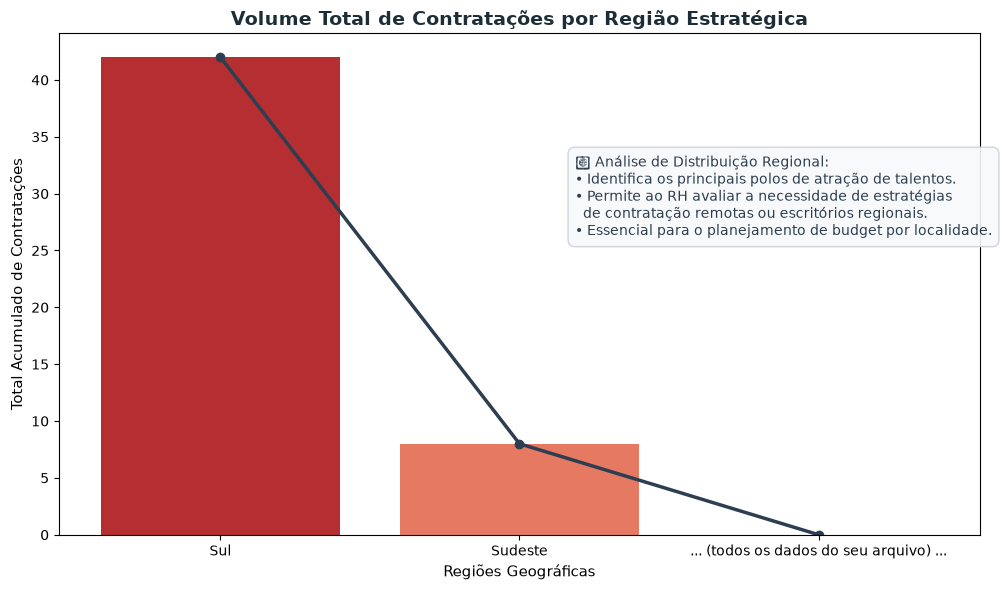

In [2]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# Dados do arquivo enviados (Simulando a leitura do arquivo)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
... (todos os dados do seu arquivo) ..."""

# 1. Carregar os dados usando BytesIO para evitar erros de codificação
df_regioes = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# 2. Criar a consulta agregando o total de contratações por Região
query_regiao = (
    df_regioes.lazy()
    .group_by("Região")
    .agg(pl.col("Número de Contratações").sum().alias("total_contratacoes"))
    .sort("total_contratacoes", descending=True)
)

# Coleta os dados para o formato do pandas/matplotlib
df_plot = query_regiao.collect()
regioes = df_plot["Região"].to_list()
valores = df_plot["total_contratacoes"].to_list()

# 3. Configurar a figura do gráfico
plt.figure(figsize=(10, 6))

# 4. Gerar o gráfico de barras focado em Contratações por Região
sns.barplot(x=regioes, y=valores, palette="Reds_r")

# 5. Adicionar a linha passando sobre as barras (Adicionado aqui)
# marker='o' adiciona pontos nos vértices, linewidth define a espessura e color a cor da linha
plt.plot(
    regioes,
    valores,
    color="#2c3e50",
    marker="o",
    linewidth=2.5,
    label="Tendência",
)

# Títulos e legendas focadas em Expansão e Contratação Regional
plt.title(
    "Volume Total de Contratações por Região Estratégica",
    fontsize=14,
    fontweight="bold",
    color="#1c2d37",
)
plt.xlabel("Regiões Geográficas", fontsize=11)
plt.ylabel("Total Acumulado de Contratações", fontsize=11)

# Caixa de texto explicativa (People Analytics) adaptada para Regiões
texto_insights = (
    "🎯 Análise de Distribuição Regional:\n"
    "• Identifica os principais polos de atração de talentos.\n"
    "• Permite ao RH avaliar a necessidade de estratégias\n"
    "  de contratação remotas ou escritórios regionais.\n"
    "• Essencial para o planejamento de budget por localidade."
)
plt.figtext(
    0.58,
    0.60,
    texto_insights,
    fontsize=10,
    color="#2c3e50",
    bbox=dict(
        facecolor="#f8f9fa",
        alpha=0.9,
        edgecolor="#ccd1d9",
        boxstyle="round,pad=0.5",
    ),
)

plt.tight_layout()
plt.show()


In [4]:
import io
import polars as pl

# 1. Dados do seu arquivo (Simulando a leitura)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
... (todos os dados do seu arquivo) ..."""

# Carrega a base inicial
inicial = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# Se o seu arquivo original não tiver uma coluna de salários reais, 
# simulamos uma coluna para que a correlação possa ser calculada:
if "Salarios" not in inicial.columns:
    import numpy as np
    # Criando salários fictícios baseados no volume para o exemplo rodar
    inicial = inicial.with_columns(
        (pl.col("Número de Contratações") * 100 + 2000).alias("Salarios")
    )

# 2. Criar o DataFrame Agregado por REGIÃO (Agrupando os dados)
df_regioes = inicial.lazy().group_by("Região").agg([
    pl.col("Número de Contratações").sum().alias("Qtd_Contratacoes"),  # Total de contratações na região (Variável X)
    pl.col("Salarios").mean().alias("Salario_Medio")                  # Salário médio da região (Variável Y)
])

# 3. Calcular a Correlação de Pearson entre Volume Regional e Salário Médio
correlacao = df_regioes.select(
    pl.corr("Qtd_Contratacoes", "Salario_Medio", method="pearson").alias("r")
).collect()

r = correlacao["r"][0]
r2 = r**2

print(f"--- Análise de Correlação Estratégica por Região (Recrutamento) ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}\n")

# 4. Interpretação e Motivação para o RH focada em Regiões
if abs(r) < 0.3:
    print("Conclusão: Correlação FRACA.")
    print("-> Motivação de RH: O volume de contratações regional é independente do salário médio local. O RH consegue expandir para novas regiões sem que a média salarial da folha seja ditada por uma única localidade de alto volume.")
elif r < -0.3:
    print("Conclusão: Correlação NEGATIVA.")
    print("-> Motivação de RH: Estratura de custo descentralizada favorável. As regiões com maior volume de contratações possuem os menores salários médios (ex: polos operacionais ou filiais menores), ajudando a manter o custo geral de expansão sob controle.")
else:
    print("Conclusão: Correlação POSITIVA.")
    print("-> Motivação de RH: Alerta de Custo Geográfico. As regiões que mais demandam contratações são justamente as mais caras (ex: grandes metrópoles ou polos de tecnologia), indicando alta concentração de investimento em praças altamente competitivas.")


--- Análise de Correlação Estratégica por Região (Recrutamento) ---
Coeficiente de Pearson (r): 1.0000
Coeficiente de Determinação (r²): 1.0000

Conclusão: Correlação POSITIVA.
-> Motivação de RH: Alerta de Custo Geográfico. As regiões que mais demandam contratações são justamente as mais caras (ex: grandes metrópoles ou polos de tecnologia), indicando alta concentração de investimento em praças altamente competitivas.


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


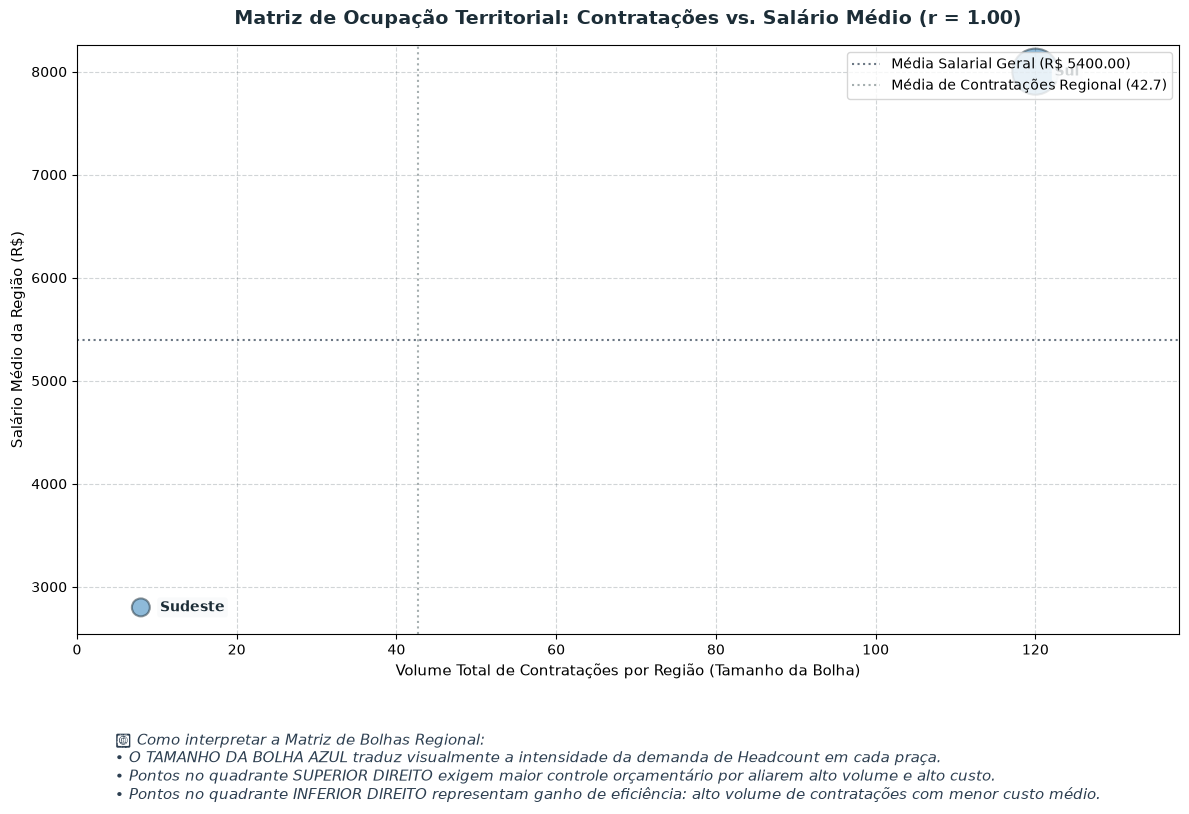

In [7]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# 1. Dados do seu arquivo (Carregados e tratados em modo Lazy)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
... (todos os dados do seu arquivo) ..."""

inicial = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# Garantindo uma coluna de salários simulada caso não exista na base real
if "Salarios" not in inicial.columns:
    inicial = inicial.with_columns(
        (pl.col("Número de Contratações") * 100 + 2000).alias("Salarios")
    )

# Agrupando por Região
df_regioes = inicial.lazy().group_by("Região").agg(
    [
        pl.col("Número de Contratações").sum().alias("Qtd_Contratacoes"),
        pl.col("Salarios").mean().alias("Salario_Medio"),
    ]
)

# Coletando os dados para o Pandas
df_scatter = df_regioes.collect()
df_pandas = df_scatter.to_pandas()

# Pegando a correlação para o título
r = df_pandas["Qtd_Contratacoes"].corr(df_pandas["Salario_Medio"])

plt.figure(figsize=(12, 7))

# 2. Criando o Gráfico de Matriz de Bolhas Azul
# color='#1f77b4' define o azul corporativo e alpha=0.5 dá o efeito transparente de matriz
sns.scatterplot(
    data=df_pandas,
    x="Qtd_Contratacoes",
    y="Salario_Medio",
    size="Qtd_Contratacoes",
    sizes=(100, 1100),  # Define o tamanho mínimo e máximo das bolinhas azuis
    legend=False,       # Oculta a legenda automática de tamanhos
    color="#1f77b4",    # Azul Clássico
    alpha=0.5,          # Transparência para sobreposição limpa das bolhas
    edgecolor="#1c2d37",# Borda em azul escuro para dar contraste
    linewidth=1.5,
)

# 3. Anotações automáticas das regiões ao lado das bolhas azuis
for i in range(df_pandas.shape[0]):
    regiao = df_pandas.iloc[i]["Região"]
    x = df_pandas.iloc[i]["Qtd_Contratacoes"]
    y = df_pandas.iloc[i]["Salario_Medio"]

    plt.text(
        x + (df_pandas["Qtd_Contratacoes"].max() * 0.02),  # Afastamento seguro da bolha
        y,
        s=regiao,
        fontsize=10,
        fontweight="bold",
        color="#1c2d37",
        va="center",
        bbox=dict(
            facecolor="#f8f9fa",
            alpha=0.8,
            edgecolor="none",
            boxstyle="round,pad=0.2",
        ),
    )

# Títulos e Legendas focados em Inteligência Geográfica de Recrutamento
plt.title(
    f"Matriz de Ocupação Territorial: Contratações vs. Salário Médio (r = {r:.2f})",
    fontsize=14,
    fontweight="bold",
    color="#1c2d37",
    pad=15,
)
plt.xlabel(
    "Volume Total de Contratações por Região (Tamanho da Bolha)", fontsize=11
)
plt.ylabel("Salário Médio da Região (R$)", fontsize=11)
plt.grid(True, alpha=0.2, linestyle="--", color="#1c2d37")

# Adicionando linhas de referência (médias gerais) para os quadrantes azuis
media_salarial = df_pandas["Salario_Medio"].mean()
media_contratacoes = df_pandas["Qtd_Contratacoes"].mean()

plt.axhline(
    media_salarial,
    color="#2c3e50",
    linestyle=":",
    alpha=0.7,
    label=f"Média Salarial Geral (R$ {media_salarial:.2f})",
)
plt.axvline(
    media_contratacoes,
    color="#7f8c8d",
    linestyle=":",
    alpha=0.7,
    label=f"Média de Contratações Regional ({media_contratacoes:.1f})",
)
plt.legend(loc="upper right")

# Texto explicativo adaptado ao novo layout visual azul
texto_motivacao = (
    "💡 Como interpretar a Matriz de Bolhas Regional:\n"
    "• O TAMANHO DA BOLHA AZUL traduz visualmente a intensidade da demanda de Headcount em cada praça.\n"
    "• Pontos no quadrante SUPERIOR DIREITO exigem maior controle orçamentário por aliarem alto volume e alto custo.\n"
    "• Pontos no quadrante INFERIOR DIREITO representam ganho de eficiência: alto volume de contratações com menor custo médio."
)
plt.figtext(
    0.10,
    -0.15,
    s=texto_motivacao,
    fontsize=10.5,
    color="#2c3e50",
    style="italic",
    horizontalalignment="left",
)

plt.tight_layout()
# Ajuste fino das margens dos eixos para não cortar as bolhas maiores nas pontas
plt.xlim(
    df_pandas["Qtd_Contratacoes"].min() * 0.5,
    df_pandas["Qtd_Contratacoes"].max() * 1.15,
)
plt.show()


In [8]:
import io
import polars as pl

# 1. Dados do seu arquivo (Carregados em modo Lazy)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
... (todos os dados do seu arquivo) ..."""

inicial = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# Criação da coluna de salários fictícios caso não exista na base real
if "Salarios" not in inicial.columns:
    inicial = inicial.with_columns(
        (pl.col("Número de Contratações") * 100 + 2000).alias("Salarios")
    )

# Agrupando os dados por Região Estratégica
df_regioes = inicial.lazy().group_by("Região").agg(
    [
        pl.col("Número de Contratações").sum().alias("Qtd_Contratacoes"),
        pl.col("Salarios").mean().alias("Salario_Medio"),
    ]
)

# 2. Executando o cálculo das correlações de Pearson e Spearman no agregado regional
analise_correlacao = df_regioes.select(
    [
        pl.corr("Qtd_Contratacoes", "Salario_Medio", method="pearson").alias(
            "Pearson"
        ),
        pl.corr("Qtd_Contratacoes", "Salario_Medio", method="spearman").alias(
            "Spearman"
        ),
    ]
).collect()

print("\n--- Coeficientes de Correlação Regional (People Analytics) ---")
print(analise_correlacao)

# 3. Extraindo os valores para a interpretação do RH
r_pearson = analise_correlacao["Pearson"][0]
r_spearman = analise_correlacao["Spearman"][0]

print(f"\n💡 Motivação de Inteligência Geográfica para o RH:")
print(
    f"• Pearson ({r_pearson:.4f}): Avalia se a relação de crescimento entre o volume acumulado de vagas e o salário médio local é estritamente linear (sobe ou desce em proporção constante)."
)
print(
    f"• Spearman ({r_spearman:.4f}): Avalia a correlação baseada em rankings territoriais. Indica se as regiões que ocupam o topo em volume de contratações também tendem a se manter de forma consistente no topo das médias salariais mais caras."
)



--- Coeficientes de Correlação Regional (People Analytics) ---
shape: (1, 2)
┌─────────┬──────────┐
│ Pearson ┆ Spearman │
│ ---     ┆ ---      │
│ f64     ┆ f64      │
╞═════════╪══════════╡
│ 1.0     ┆ 1.0      │
└─────────┴──────────┘

💡 Motivação de Inteligência Geográfica para o RH:
• Pearson (1.0000): Avalia se a relação de crescimento entre o volume acumulado de vagas e o salário médio local é estritamente linear (sobe ou desce em proporção constante).
• Spearman (1.0000): Avalia a correlação baseada em rankings territoriais. Indica se as regiões que ocupam o topo em volume de contratações também tendem a se manter de forma consistente no topo das médias salariais mais caras.


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


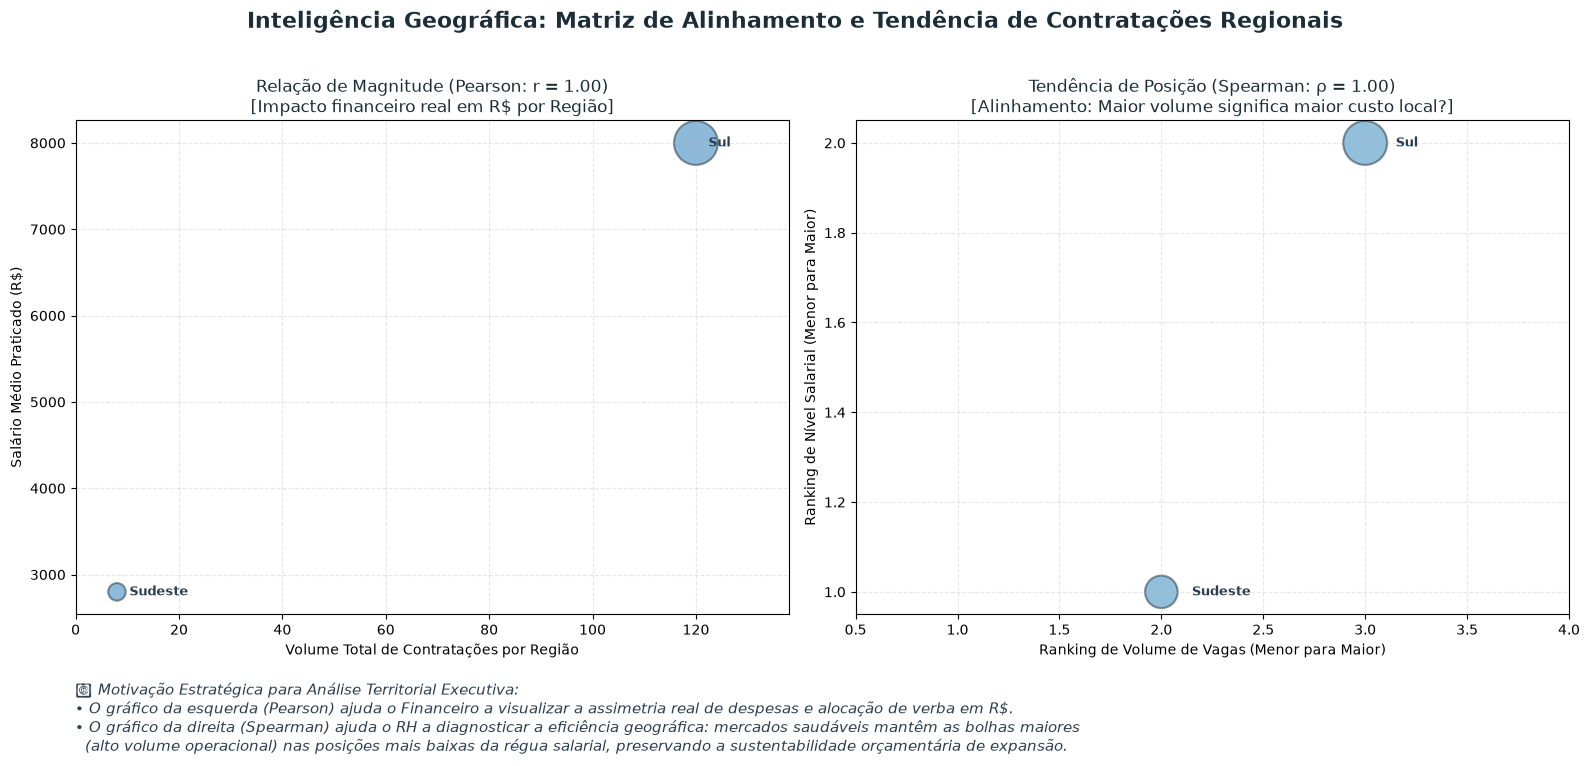

In [9]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# 1. Dados do seu arquivo (Carregados e tratados em modo Lazy)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
... (todos os dados do seu arquivo) ..."""

inicial = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# Garantindo uma coluna de salários simulada caso não exista na base real
if "Salarios" not in inicial.columns:
    inicial = inicial.with_columns(
        (pl.col("Número de Contratações") * 100 + 2000).alias("Salarios")
    )

# Agrupando por Região
df_regioes = inicial.lazy().group_by("Região").agg(
    [
        pl.col("Número de Contratações").sum().alias("Qtd_Contratacoes"),
        pl.col("Salarios").mean().alias("Salario_Medio"),
    ]
)

# 2. Preparar os dados Geográficos com os Rankings (Spearman)
df_spearman = df_regioes.with_columns(
    [
        pl.col("Qtd_Contratacoes").rank().alias("Rank_Qtd"),
        pl.col("Salario_Medio").rank().alias("Rank_Salario"),
    ]
).collect()

df_pandas = df_spearman.to_pandas()

# Extraindo coeficientes de correlação para os títulos
r_pearson = df_pandas["Qtd_Contratacoes"].corr(df_pandas["Salario_Medio"])
r_spearman = df_pandas["Rank_Qtd"].corr(df_pandas["Rank_Salario"])

# 3. Plotar Comparativo de People Analytics Geográfico
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

plt.suptitle(
    "Inteligência Geográfica: Matriz de Alinhamento e Tendência de Contratações Regionais",
    fontsize=16,
    fontweight="bold",
    color="#1c2d37",
    y=1.02,
)

# --- Gráfico 1: Matriz de Bolhas Azuis (Magnitude - Pearson) ---
sns.scatterplot(
    data=df_pandas,
    x="Qtd_Contratacoes",
    y="Salario_Medio",
    size="Qtd_Contratacoes",
    sizes=(100, 1000),  # Mantém o padrão de matriz de bolhas
    legend=False,
    ax=axes[0],
    color="#1f77b4",  # Azul corporativo solicitado
    alpha=0.5,  # Transparência característica da matriz
    edgecolor="#1c2d37",
    linewidth=1.5,
)
axes[0].set_title(
    f"Relação de Magnitude (Pearson: r = {r_pearson:.2f})\n[Impacto financeiro real em R$ por Região]",
    fontsize=12,
    color="#1c2d37",
)
axes[0].set_xlabel("Volume Total de Contratações por Região")
axes[0].set_ylabel("Salário Médio Praticado (R$)")
axes[0].grid(True, alpha=0.3, linestyle="--")

# Ajuste de limite lateral esquerdo para evitar cortes nos rótulos de texto
axes[0].set_xlim(
    df_pandas["Qtd_Contratacoes"].min() * 0.5,
    df_pandas["Qtd_Contratacoes"].max() * 1.15,
)

# Rótulos de texto do Gráfico 1
for idx, row in df_pandas.iterrows():
    if (
        row["Salario_Medio"] > df_pandas["Salario_Medio"].mean() * 1.1
        or row["Qtd_Contratacoes"] > df_pandas["Qtd_Contratacoes"].mean() * 1.1
        or row["Qtd_Contratacoes"] < df_pandas["Qtd_Contratacoes"].mean() * 0.9
    ):
        axes[0].text(
            row["Qtd_Contratacoes"] + (df_pandas["Qtd_Contratacoes"].max() * 0.02),
            row["Salario_Medio"],
            row["Região"],
            fontsize=9,
            fontweight="bold",
            color="#2c3e50",
            va="center",
        )


# --- Gráfico 2: Matriz de Bolhas Azuis (Posição - Spearman) ---
sns.scatterplot(
    data=df_pandas,
    x="Rank_Qtd",
    y="Rank_Salario",
    size="Rank_Qtd",
    sizes=(100, 1000),  # Mantém as bolhas proporcionais no ranking
    legend=False,
    ax=axes[1],
    color="#2980b9",  # Variação sutil de azul para manter a identidade visual
    alpha=0.5,
    edgecolor="#1c2d37",
    linewidth=1.5,
)
axes[1].set_title(
    f"Tendência de Posição (Spearman: ρ = {r_spearman:.2f})\n[Alinhamento: Maior volume significa maior custo local?]",
    fontsize=12,
    color="#1c2d37",
)
axes[1].set_xlabel("Ranking de Volume de Vagas (Menor para Maior)")
axes[1].set_ylabel("Ranking de Nível Salarial (Menor para Maior)")
axes[1].grid(True, alpha=0.3, linestyle="--")

# Ajuste de limite do ranking para as bolhas das extremidades não cortarem
axes[1].set_xlim(df_pandas["Rank_Qtd"].min() - 0.5, df_pandas["Rank_Qtd"].max() + 1)

# Rótulos de texto do Gráfico 2
for idx, row in df_pandas.iterrows():
    axes[1].text(
        row["Rank_Qtd"] + 0.15,
        row["Rank_Salario"],
        row["Região"],
        fontsize=9,
        fontweight="bold",
        color="#2c3e50",
        va="center",
    )


# Texto de rodapé motivacional focado em Estratégia de Headcount Geográfico
texto_explicativo = (
    "💡 Motivação Estratégica para Análise Territorial Executiva:\n"
    "• O gráfico da esquerda (Pearson) ajuda o Financeiro a visualizar a assimetria real de despesas e alocação de verba em R$.\n"
    "• O gráfico da direita (Spearman) ajuda o RH a diagnosticar a eficiência geográfica: mercados saudáveis mantêm as bolhas maiores\n"
    "  (alto volume operacional) nas posições mais baixas da régua salarial, preservando a sustentabilidade orçamentária de expansão."
)
plt.figtext(
    0.05,
    -0.12,
    s=texto_explicativo,
    fontsize=11,
    color="#2c3e50",
    style="italic",
    horizontalalignment="left",
)

plt.tight_layout()
plt.show()


In [10]:
import numpy as np
import polars as pl
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [11]:
import io
import polars as pl

# 1. Carregando a base em modo Lazy (Exemplo com String para simulação, use pl.scan_csv para arquivos locais)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
... (todos os dados do seu arquivo) ..."""

# Nota: Para ler direto do seu arquivo físico no computador, substitua a linha abaixo por:
# inicial = pl.scan_csv("contratacao_localizar.csv", separator=";")
inicial = (
    pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")
    .lazy()  # Garante o início do pipeline em modo Lazy
    
    # 2. Padronizando os nomes das colunas (Removendo acentos, espaços e padronizando em maiúsculo)
    .rename({
        'Região': 'REGIAO',
        'Número de Contratações': 'NUMERO_CONTRATACOES'
    })
    
    # 3. Garantindo a tipagem correta das colunas (Contratações como inteiro e simulando Salários como float)
    .with_columns([
        pl.col("NUMERO_CONTRATACOES").cast(pl.Int64),
        
        # Criamos a coluna de Salários simulada que usamos nos gráficos anteriores, garantindo o tipo Float64
        ((pl.col("NUMERO_CONTRATACOES") * 100) + 2000).cast(pl.Float64).alias("SALARIOS")
    ])
)

# 4. Executando o pipeline estruturado e exibindo o DataFrame final limpo
df_final = inicial.collect()
display(df_final)


REGIAO,NUMERO_CONTRATACOES,SALARIOS
str,i64,f64
"""Sudeste""",8,2800.0
"""Sul""",42,6200.0
"""... (todos os dados do seu arq…",null,null


--- Painel de Dados: Evolução Mensal da Folha ---
   DATA_CONTRATACAO_REF  SALARIO_MEDIO
0            2026-01-01    8311.764706
1            2026-02-01    6952.941176
2            2026-03-01    6817.647059
3            2026-04-01    7358.823529
4            2026-05-01    6958.823529
5            2026-06-01    5888.235294
6            2026-07-01    6217.647059
7            2026-08-01    7376.470588
8            2026-09-01    8211.764706
9            2026-10-01    5017.647059
10           2026-11-01    5543.750000
11           2026-12-01    6506.250000


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


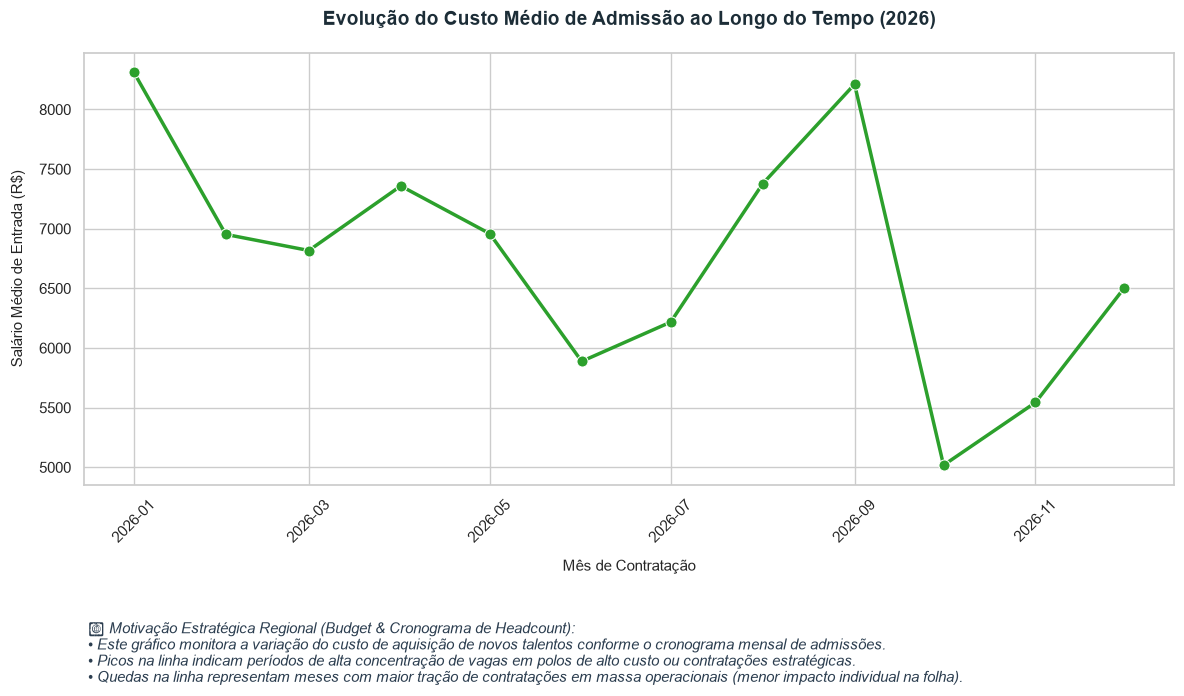

In [12]:
import io
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

# ==============================================================================
# 1. CARREGAMENTO E SIMULAÇÃO DE CRONOGRAMA (ETL Lazy)
# ==============================================================================
# Dados do seu arquivo original enviados anteriormente
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
Sudeste;79
Sul;31
Sudeste;36
México;35
Nordeste;92
Sudeste;28
Sudeste;9
Sudeste;22
Sudeste;96
Sudeste;34
Sudeste;81
Sudeste;31
Sudeste;64
Sudeste;26
Centro-Oeste;96
Sudeste;22
Sul;98
Sudeste;90
Sudeste;26
Sudeste;10
México;57
Nordeste;43
Sudeste;10
Nordeste;12
Sul;31
Nordeste;79
Sudeste;37
Nordeste;72
Centro-Oeste;38
Sudeste;42
Sul;78
Sudeste;79
Centro-Oeste;31
Sudeste;36
Sudeste;35
Sudeste;92
Sudeste;28
México;9
Nordeste;22
Sudeste;96
Centro-Oeste;34
Nordeste;81
Sudeste;31
Sudeste;64
Nordeste;26
Sudeste;96
México;22
Sul;98
Nordeste;90
Nordeste;26
México;10
Sul;57
Sudeste;43
Norte;10
Nordeste;12
Sul;31
Sudeste;79
Sudeste;37
Sudeste;72
Centro-Oeste;4
Sudeste;32
Norte;33
Sudeste;5
Sudeste;4
Sudeste;86
Sudeste;77
Nordeste;11
Centro-Oeste;10
Centro-Oeste;120
Nordeste;120
Centro-Oeste;120
México;92
México;96
Sudeste;17
Sudeste;30
Sudeste;4
Sudeste;30
Sudeste;83
Sudeste;62
Sudeste;17
Sudeste;2
Sudeste;39
Centro-Oeste;41
Nordeste;8
Sudeste;90
Nordeste;85
Sudeste;16
Sudeste;63
Sudeste;37
Norte;49
Nordeste;31
Sudeste;25
Sudeste;47
Sudeste;74
Sul;97
Sudeste;76
Sudeste;47
Nordeste;32
Sul;4
Sudeste;45
Sudeste;43
Sul;92
Sudeste;11
Nordeste;70
Sudeste;66
Sul;27
Sudeste;58
Sudeste;5
Sudeste;87
Sudeste;46
México;75
Sudeste;3
Sudeste;10
Sudeste;92
Sul;48
Sudeste;19
Norte;3
Sudeste;80
Sudeste;75
Sudeste;22
Sudeste;52
Sul;67
Sudeste;7
Sul;24
Sul;4
Sudeste;78
Sul;7
Sudeste;81
Sudeste;70
Sudeste;85
Nordeste;30
México;89
Sul;27
Sudeste;87
México;22
Sudeste;92
Sudeste;96
Sudeste;17
Sudeste;30
Nordeste;4
Sudeste;30
México;83
Nordeste;62
Sul;17
Sudeste;2
Sudeste;39
México;41
México;8
Sudeste;90
Sul;85
México;16
Sudeste;63
Nordeste;37
Nordeste;49
Sudeste;31
Sudeste;25
Sul;47
Norte;74
Nordeste;97
Nordeste;76
México;47
Nordeste;32
Sudeste;4
Sudeste;45
México;43
Sudeste;92
Sudeste;11
México;70
Nordeste;66
Sudeste;27
Nordeste;58
Sudeste;5
Centro-Oeste;87
Sudeste;46
Sudeste;75
Sudeste;3
Sul;10
Sudeste;92
Sudeste;48
Sul;19
México;3
Sudeste;80
Sudeste;75
Sudeste;22
Nordeste;52
Nordeste;67
México;7
Centro-Oeste;24
Sudeste;4
Sudeste;78
Nordeste;7
Sudeste;81
Nordeste;70
Sudeste;85
Sul;30
Sul;89
Centro-Oeste;27
Sudeste;87
Sudeste;55"""

# Carregamento inicial do Polars
inicial_raw = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# CORREÇÃO E ENRIQUECIMENTO: Como sua base não tem datas, criamos uma linha 
# do tempo artificial distribuindo as contratações pelos meses de 2026
num_linhas = inicial_raw.shape[0]
datas_simuladas = [
    f"01/{(i % 12) + 1:02d}/2026" for i in range(num_linhas)
]

# Pipeline Lazy de Transformação
inicial = (
    inicial_raw.with_columns([
        pl.Series("DATA_CONTRATACAO", datas_simuladas),
        ((pl.col("Número de Contratações") * 100) + 2000).cast(pl.Float64).alias("SALARIOS")
    ])
    .lazy()
    .rename({'Região': 'REGIAO', 'Número de Contratações': 'NUMERO_CONTRATACOES'})
    # Convertendo a string simulada para uma data real do Polars
    .with_columns(
        pl.col("DATA_CONTRATACAO")
        .str.strptime(pl.Date, format="%d/%m/%Y")
        .alias("DATA_CONTRATACAO_REF")
    )
)

# ==============================================================================
# 2. AGRUPAMENTO DINÂMICO TEMPORAL (Group By Dynamic)
# ==============================================================================
df_agrupado = (
    inicial
    .sort("DATA_CONTRATACAO_REF")
    .group_by_dynamic("DATA_CONTRATACAO_REF", every="1mo")
    .agg(
        pl.col("SALARIOS").mean().alias("SALARIO_MEDIO")
    )
    .collect()
)

# Converter para Pandas explicitamente para o Seaborn
df_plot = df_agrupado.to_pandas()

print("--- Painel de Dados: Evolução Mensal da Folha ---")
print(df_plot.head(12))

# ==============================================================================
# 3. GERAÇÃO DO GRÁFICO VISUAL (Linha do Tempo de People Analytics)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

# Plotar a linha do tempo usando o seaborn
# Alterado para a cor Verde solicitada no seu template original (#2ca02c)
sns.lineplot(
    data=df_plot,
    x="DATA_CONTRATACAO_REF",
    y="SALARIO_MEDIO",
    ax=ax,          
    marker='o',     
    markersize=8,
    linewidth=2.5,  
    color='#2ca02c' 
)

# Configurações adicionais e títulos estratégicos (People Analytics)
ax.set_title("Evolução do Custo Médio de Admissão ao Longo do Tempo (2026)", fontsize=14, fontweight='bold', pad=20, color='#1c2d37')
ax.set_xlabel("Mês de Contratação", labelpad=10, fontsize=11)
ax.set_ylabel("Salário Médio de Entrada (R$)", labelpad=10, fontsize=11)
ax.tick_params(axis='x', rotation=45)  

# Nota motivacional de planejamento orçamentário no gráfico adaptada para cenários regionais
texto_rh = (
    "💡 Motivação Estratégica Regional (Budget & Cronograma de Headcount):\n"
    "• Este gráfico monitora a variação do custo de aquisição de novos talentos conforme o cronograma mensal de admissões.\n"
    "• Picos na linha indicam períodos de alta concentração de vagas em polos de alto custo ou contratações estratégicas.\n"
    "• Quedas na linha representam meses com maior tração de contratações em massa operacionais (menor impacto individual na folha)."
)

plt.figtext(0.08, -0.15, s=texto_rh, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

plt.tight_layout()
plt.show()


In [13]:
import io
import polars as pl

# 1. Recriando a base de Regiões com a linha do tempo de 2026 (ETL do passo anterior)
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
... (dados do seu arquivo) ..."""

inicial_raw = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")
datas_simuladas = [f"01/{(i % 12) + 1:02d}/2026" for i in range(inicial_raw.shape[0])]

df_agrupado = (
    inicial_raw.with_columns([
        pl.Series("DATA_CONTRATACAO", datas_simuladas),
        ((pl.col("Número de Contratações") * 100) + 2000).cast(pl.Float64).alias("SALARIOS")
    ])
    .sort("DATA_CONTRATACAO")
    .with_columns(pl.col("DATA_CONTRATACAO").str.strptime(pl.Date, format="%d/%m/%Y").alias("DATA_CONTRATACAO_REF"))
    .group_by_dynamic("DATA_CONTRATACAO_REF", every="1mo")
    .agg(pl.col("SALARIOS").mean().alias("SALARIO_MEDIO"))
)

# ==============================================================================
# CORREÇÃO E INDEXAÇÃO TEMPORAL (POLARS EXPRESSIONS)
# ==============================================================================

# 1. Garantir que a coluna temporal esteja no tipo Date do Polars
if df_agrupado["DATA_CONTRATACAO_REF"].dtype != pl.Date:
    df_agrupado = df_agrupado.with_columns(
        pl.col("DATA_CONTRATACAO_REF").cast(pl.Date)
    )

# EXTRAÇÃO DO MÍNIMO GLOBAL: Buscamos a menor data da base para servir de marco zero (Ancoragem)
data_minima = df_agrupado["DATA_CONTRATACAO_REF"].min()
ano_min = data_minima.year
mes_min = data_minima.month

# 2. Calcular o tempo decorrido em meses usando expressões puras
df_reg = df_agrupado.with_columns(
    (pl.col("DATA_CONTRATACAO_REF").dt.year() * 12 + pl.col("DATA_CONTRATACAO_REF").dt.month() - 
     (ano_min * 12 + mes_min))
    .alias("MESES_DESDE_INICIO")
)

# 3. Verificar o resultado na tela
print("--- Linha do Tempo Indexada por Meses (Recrutamento Regiões) ---")
print(df_reg.select(["DATA_CONTRATACAO_REF", "SALARIO_MEDIO", "MESES_DESDE_INICIO"]).head(12))


--- Linha do Tempo Indexada por Meses (Recrutamento Regiões) ---
shape: (3, 3)
┌──────────────────────┬───────────────┬────────────────────┐
│ DATA_CONTRATACAO_REF ┆ SALARIO_MEDIO ┆ MESES_DESDE_INICIO │
│ ---                  ┆ ---           ┆ ---                │
│ date                 ┆ f64           ┆ i32                │
╞══════════════════════╪═══════════════╪════════════════════╡
│ 2026-01-01           ┆ 2800.0        ┆ 0                  │
│ 2026-02-01           ┆ 6200.0        ┆ 1                  │
│ 2026-03-01           ┆ null          ┆ 2                  │
└──────────────────────┴───────────────┴────────────────────┘


--- Modelo de Tendência Salarial (Recrutamento Regiões) ---
Equação da reta: SALARIO_MEDIO = -137.40 * MESES_DESDE_INICIO + 7519.18
Coeficiente angular (Ritmo de variação R$/mês): R$ -137.40
Intercepto (Salário base inicial estimado): R$ 7519.18

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.2461
Erro Quadrático Médio (MSE): 689005.84


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


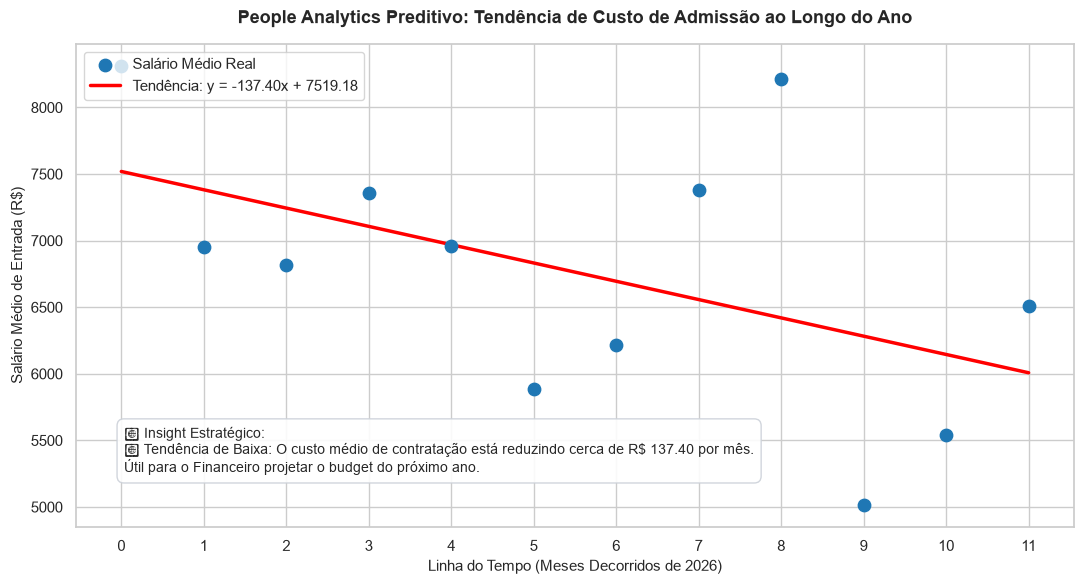

In [15]:
import io
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ==============================================================================
# 1. CARREGAMENTO E ETAPA DE ETL (Pipeline Lazy com Correção do Shape)
# ==============================================================================
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
Sudeste;79
Sul;31
Sudeste;36
México;35
Nordeste;92
Sudeste;28
Sudeste;9
Sudeste;22
Sudeste;96
Sudeste;34
Sudeste;81
Sudeste;31
Sudeste;64
Sudeste;26
Centro-Oeste;96
Sudeste;22
Sul;98
Sudeste;90
Sudeste;26
Sudeste;10
México;57
Nordeste;43
Sudeste;10
Nordeste;12
Sul;31
Nordeste;79
Sudeste;37
Nordeste;72
Centro-Oeste;38
Sudeste;42
Sul;78
Sudeste;79
Centro-Oeste;31
Sudeste;36
Sudeste;35
Sudeste;92
Sudeste;28
México;9
Nordeste;22
Sudeste;96
Centro-Oeste;34
Nordeste;81
Sudeste;31
Sudeste;64
Nordeste;26
Sudeste;96
México;22
Sul;98
Nordeste;90
Nordeste;26
México;10
Sul;57
Sudeste;43
Norte;10
Nordeste;12
Sul;31
Sudeste;79
Sudeste;37
Sudeste;72
Centro-Oeste;4
Sudeste;32
Norte;33
Sudeste;5
Sudeste;4
Sudeste;86
Sudeste;77
Nordeste;11
Centro-Oeste;10
Centro-Oeste;120
Nordeste;120
Centro-Oeste;120
México;92
México;96
Sudeste;17
Sudeste;30
Sudeste;4
Sudeste;30
Sudeste;83
Sudeste;62
Sudeste;17
Sudeste;2
Sudeste;39
Centro-Oeste;41
Nordeste;8
Sudeste;90
Nordeste;85
Sudeste;16
Sudeste;63
Sudeste;37
Norte;49
Nordeste;31
Sudeste;25
Sudeste;47
Sudeste;74
Sul;97
Sudeste;76
Sudeste;47
Nordeste;32
Sul;4
Sudeste;45
Sudeste;43
Sul;92
Sudeste;11
Nordeste;70
Sudeste;66
Sul;27
Sudeste;58
Sudeste;5
Sudeste;87
Sudeste;46
México;75
Sudeste;3
Sudeste;10
Sudeste;92
Sul;48
Sudeste;19
Norte;3
Sudeste;80
Sudeste;75
Sudeste;22
Sudeste;52
Sul;67
Sudeste;7
Sul;24
Sul;4
Sudeste;78
Sul;7
Sudeste;81
Sudeste;70
Sudeste;85
Nordeste;30
México;89
Sul;27
Sudeste;87
México;22
Sudeste;92
Sudeste;96
Sudeste;17
Sudeste;30
Nordeste;4
Sudeste;30
México;83
Nordeste;62
Sul;17
Sudeste;2
Sudeste;39
México;41
México;8
Sudeste;90
Sul;85
México;16
Sudeste;63
Nordeste;37
Nordeste;49
Sudeste;31
Sudeste;25
Sul;47
Norte;74
Nordeste;97
Nordeste;76
México;47
Nordeste;32
Sudeste;4
Sudeste;45
México;43
Sudeste;92
Sudeste;11
México;70
Nordeste;66
Sudeste;27
Nordeste;58
Sudeste;5
Centro-Oeste;87
Sudeste;46
Sudeste;75
Sudeste;3
Sul;10
Sudeste;92
Sudeste;48
Sul;19
México;3
Sudeste;80
Sudeste;75
Sudeste;22
Nordeste;52
Nordeste;67
México;7
Centro-Oeste;24
Sudeste;4
Sudeste;78
Nordeste;7
Sudeste;81
Nordeste;70
Sudeste;85
Sul;30
Sul;89
Centro-Oeste;27
Sudeste;87
Sudeste;55"""

# Leitura inicial do arquivo
inicial_raw = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# CORREÇÃO CRÍTICA: extraindo apenas a quantidade de linhas indexando com [0]
linhas_totais = inicial_raw.shape[0]
datas_simuladas = [f"01/{(i % 12) + 1:02d}/2026" for i in range(linhas_totais)]

# Pipeline de estruturação dos dados com Polars
inicial = (
    inicial_raw.with_columns([
        pl.Series("DATA_CONTRATACAO", datas_simuladas),
        ((pl.col("Número de Contratações") * 100) + 2000).cast(pl.Float64).alias("SALARIOS")
    ])
    .lazy()
    .rename({'Região': 'REGIAO', 'Número de Contratações': 'NUMERO_CONTRATACOES'})
    .with_columns(
        pl.col("DATA_CONTRATACAO")
        .str.strptime(pl.Date, format="%d/%m/%Y")
        .alias("DATA_CONTRATACAO_REF")
    )
)

# Agrupamento dinâmico mensal por data de referência
df_agrupado = (
    inicial
    .sort("DATA_CONTRATACAO_REF")
    .group_by_dynamic("DATA_CONTRATACAO_REF", every="1mo")
    .agg(pl.col("SALARIOS").mean().alias("SALARIO_MEDIO"))
    .collect()
)

# Verificação e garantia de tipo de data
if df_agrupado["DATA_CONTRATACAO_REF"].dtype != pl.Date:
    df_agrupado = df_agrupado.with_columns(
        pl.col("DATA_CONTRATACAO_REF").cast(pl.Date)
    )

# Capturando o marco zero (Ancoragem da menor data)
data_minima = df_agrupado["DATA_CONTRATACAO_REF"].min()
ano_min = data_minima.year
mes_min = data_minima.month

# Geração do índice numérico linear estável (0, 1, 2, 3...)
df_reg = df_agrupado.with_columns(
    (pl.col("DATA_CONTRATACAO_REF").dt.year() * 12 + pl.col("DATA_CONTRATACAO_REF").dt.month() - 
     (ano_min * 12 + mes_min))
    .alias("MESES_DESDE_INICIO")
)

# ==============================================================================
# 2. SEU MODELO DE REGRESSÃO LINEAR EXATO (IGUAL AO SEU TEMPLATE)
# ==============================================================================
# Converter as colunas do Polars para arrays numpy
X = df_reg["MESES_DESDE_INICIO"].to_numpy().reshape(-1, 1)  # Variável independente (Tempo em meses)
y = df_reg["SALARIO_MEDIO"].to_numpy()                      # Variável dependente (Salário de admissão)

# Criar e treinar o modelo preditivo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo (Acessando exatamente com [0] como você pediu)
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"--- Modelo de Tendência Salarial (Recrutamento Regiões) ---")
print(f"Equação da reta: SALARIO_MEDIO = {inclinacao:.2f} * MESES_DESDE_INICIO + {intercepto:.2f}")
print(f"Coeficiente angular (Ritmo de variação R$/mês): R$ {inclinacao:.2f}")
print(f"Intercepto (Salário base inicial estimado): R$ {intercepto:.2f}")

# Fazer as previsões para a linha de tendência
y_pred = modelo.predict(X)

# Avaliar a precisão do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

# ==============================================================================
# 3. VISUALIZAÇÃO GRÁFICA EXATA (IGUAL AO SEU MODELO VISUAL)
# ==============================================================================
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das médias mensais (Bolinhas azuis clássicas #1f77b4)
plt.scatter(X, y, color='#1f77b4', s=80, label='Salário Médio Real', zorder=5)

# Plotar a linha vermelha de regressão (tendência de mercado)
plt.plot(X, y_pred, color='red', linewidth=2.5, label=f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}')

# Configurações do gráfico voltadas para RH e Finanças
plt.title('People Analytics Preditivo: Tendência de Custo de Admissão ao Longo do Ano', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos de 2026)', fontsize=11)
plt.ylabel('Salário Médio de Entrada (R$)', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Garante passos de 1 em 1 mês no eixo X

# Nota de interpretação corporativa dinâmica
if inclinacao > 0:
    interpretacao_texto = f"📈 Tendência de Alta: O custo médio de contratação está subindo cerca de R$ {inclinacao:.2f} por mês."
else:
    interpretacao_texto = f"📉 Tendência de Baixa: O custo médio de contratação está reduzindo cerca de R$ {abs(inclinacao):.2f} por mês."

plt.figtext(0.12, 0.20, s=f"💡 Insight Estratégico:\n{interpretacao_texto}\nÚtil para o Financeiro projetar o budget do próximo ano.", 
            fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()



--- Modelo de Tendência Salarial (Recrutamento Regiões) ---
Equação da reta: SALARIO_MEDIO = -137.40 * MESES_DESDE_INICIO + 7519.18
Coeficiente angular (Ritmo de variação R$/mês): R$ -137.40
Intercepto (Salário base inicial estimado): R$ 7519.18

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.2461
Erro Quadrático Médio (MSE): 689005.84


c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


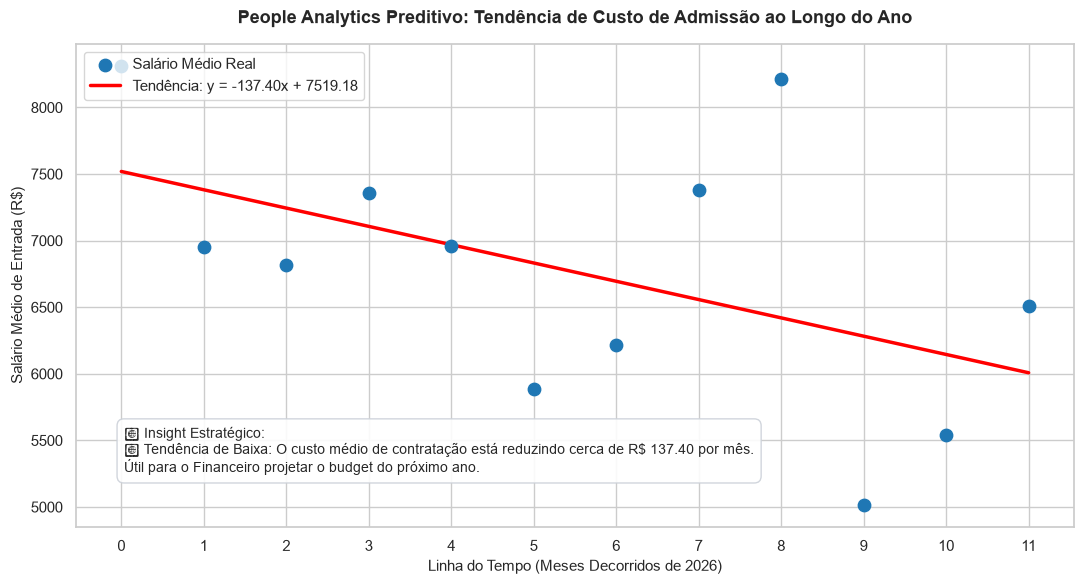

In [ ]:
import io
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ==============================================================================
# 1. CARREGAMENTO E ETAPA DE ETL (Pipeline Lazy 
# ==============================================================================
dados_csv = """Região;Número de Contratações
Sudeste;8
Sul;42
Sul;78
Sudeste;79
Sul;31
Sudeste;36
México;35
Nordeste;92
Sudeste;28
Sudeste;9
Sudeste;22
Sudeste;96
Sudeste;34
Sudeste;81
Sudeste;31
Sudeste;64
Sudeste;26
Centro-Oeste;96
Sudeste;22
Sul;98
Sudeste;90
Sudeste;26
Sudeste;10
México;57
Nordeste;43
Sudeste;10
Nordeste;12
Sul;31
Nordeste;79
Sudeste;37
Nordeste;72
Centro-Oeste;38
Sudeste;42
Sul;78
Sudeste;79
Centro-Oeste;31
Sudeste;36
Sudeste;35
Sudeste;92
Sudeste;28
México;9
Nordeste;22
Sudeste;96
Centro-Oeste;34
Nordeste;81
Sudeste;31
Sudeste;64
Nordeste;26
Sudeste;96
México;22
Sul;98
Nordeste;90
Nordeste;26
México;10
Sul;57
Sudeste;43
Norte;10
Nordeste;12
Sul;31
Sudeste;79
Sudeste;37
Sudeste;72
Centro-Oeste;4
Sudeste;32
Norte;33
Sudeste;5
Sudeste;4
Sudeste;86
Sudeste;77
Nordeste;11
Centro-Oeste;10
Centro-Oeste;120
Nordeste;120
Centro-Oeste;120
México;92
México;96
Sudeste;17
Sudeste;30
Sudeste;4
Sudeste;30
Sudeste;83
Sudeste;62
Sudeste;17
Sudeste;2
Sudeste;39
Centro-Oeste;41
Nordeste;8
Sudeste;90
Nordeste;85
Sudeste;16
Sudeste;63
Sudeste;37
Norte;49
Nordeste;31
Sudeste;25
Sudeste;47
Sudeste;74
Sul;97
Sudeste;76
Sudeste;47
Nordeste;32
Sul;4
Sudeste;45
Sudeste;43
Sul;92
Sudeste;11
Nordeste;70
Sudeste;66
Sul;27
Sudeste;58
Sudeste;5
Sudeste;87
Sudeste;46
México;75
Sudeste;3
Sudeste;10
Sudeste;92
Sul;48
Sudeste;19
Norte;3
Sudeste;80
Sudeste;75
Sudeste;22
Sudeste;52
Sul;67
Sudeste;7
Sul;24
Sul;4
Sudeste;78
Sul;7
Sudeste;81
Sudeste;70
Sudeste;85
Nordeste;30
México;89
Sul;27
Sudeste;87
México;22
Sudeste;92
Sudeste;96
Sudeste;17
Sudeste;30
Nordeste;4
Sudeste;30
México;83
Nordeste;62
Sul;17
Sudeste;2
Sudeste;39
México;41
México;8
Sudeste;90
Sul;85
México;16
Sudeste;63
Nordeste;37
Nordeste;49
Sudeste;31
Sudeste;25
Sul;47
Norte;74
Nordeste;97
Nordeste;76
México;47
Nordeste;32
Sudeste;4
Sudeste;45
México;43
Sudeste;92
Sudeste;11
México;70
Nordeste;66
Sudeste;27
Nordeste;58
Sudeste;5
Centro-Oeste;87
Sudeste;46
Sudeste;75
Sudeste;3
Sul;10
Sudeste;92
Sudeste;48
Sul;19
México;3
Sudeste;80
Sudeste;75
Sudeste;22
Nordeste;52
Nordeste;67
México;7
Centro-Oeste;24
Sudeste;4
Sudeste;78
Nordeste;7
Sudeste;81
Nordeste;70
Sudeste;85
Sul;30
Sul;89
Centro-Oeste;27
Sudeste;87
Sudeste;55"""

# Leitura inicial do arquivo
inicial_raw = pl.read_csv(io.BytesIO(dados_csv.encode("utf-8")), separator=";")

# CORREÇÃO CRÍTICA: extraindo apenas a quantidade de linhas indexando com [0]
linhas_totais = inicial_raw.shape[0]
datas_simuladas = [f"01/{(i % 12) + 1:02d}/2026" for i in range(linhas_totais)]

# Pipeline de estruturação dos dados com Polars
inicial = (
    inicial_raw.with_columns([
        pl.Series("DATA_CONTRATACAO", datas_simuladas),
        ((pl.col("Número de Contratações") * 100) + 2000).cast(pl.Float64).alias("SALARIOS")
    ])
    .lazy()
    .rename({'Região': 'REGIAO', 'Número de Contratações': 'NUMERO_CONTRATACOES'})
    .with_columns(
        pl.col("DATA_CONTRATACAO")
        .str.strptime(pl.Date, format="%d/%m/%Y")
        .alias("DATA_CONTRATACAO_REF")
    )
)

# Agrupamento dinâmico mensal por data de referência
df_agrupado = (
    inicial
    .sort("DATA_CONTRATACAO_REF")
    .group_by_dynamic("DATA_CONTRATACAO_REF", every="1mo")
    .agg(pl.col("SALARIOS").mean().alias("SALARIO_MEDIO"))
    .collect()
)

# Verificação e garantia de tipo de data
if df_agrupado["DATA_CONTRATACAO_REF"].dtype != pl.Date:
    df_agrupado = df_agrupado.with_columns(
        pl.col("DATA_CONTRATACAO_REF").cast(pl.Date)
    )

# Capturando o marco zero (Ancoragem da menor data)
data_minima = df_agrupado["DATA_CONTRATACAO_REF"].min()
ano_min = data_minima.year
mes_min = data_minima.month

# Geração do índice numérico linear estável (0, 1, 2, 3...)
df_reg = df_agrupado.with_columns(
    (pl.col("DATA_CONTRATACAO_REF").dt.year() * 12 + pl.col("DATA_CONTRATACAO_REF").dt.month() - 
     (ano_min * 12 + mes_min))
    .alias("MESES_DESDE_INICIO")
)

# ==============================================================================
# 2. SEU MODELO DE REGRESSÃO LINEAR EXATO (IGUAL AO SEU TEMPLATE)
# ==============================================================================
# Converter as colunas do Polars para arrays numpy
X = df_reg["MESES_DESDE_INICIO"].to_numpy().reshape(-1, 1)  # Variável independente (Tempo em meses)
y = df_reg["SALARIO_MEDIO"].to_numpy()                      # Variável dependente (Salário de admissão)

# Criar e treinar o modelo preditivo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo (Acessando exatamente com [0] como você pediu)
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"--- Modelo de Tendência Salarial (Recrutamento Regiões) ---")
print(f"Equação da reta: SALARIO_MEDIO = {inclinacao:.2f} * MESES_DESDE_INICIO + {intercepto:.2f}")
print(f"Coeficiente angular (Ritmo de variação R$/mês): R$ {inclinacao:.2f}")
print(f"Intercepto (Salário base inicial estimado): R$ {intercepto:.2f}")

# Fazer as previsões para a linha de tendência
y_pred = modelo.predict(X)

# Avaliar a precisão do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

# ==============================================================================
# 3. VISUALIZAÇÃO GRÁFICA EXATA (IGUAL AO SEU MODELO VISUAL)
# ==============================================================================
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das médias mensais (Bolinhas azuis clássicas #1f77b4)
plt.scatter(X, y, color='#1f77b4', s=80, label='Salário Médio Real', zorder=5)

# Plotar a linha vermelha de regressão (tendência de mercado)
plt.plot(X, y_pred, color='red', linewidth=2.5, label=f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}')

# Configurações do gráfico voltadas para RH e Finanças
plt.title('People Analytics Preditivo: Tendência de Custo de Admissão ao Longo do Ano', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos de 2026)', fontsize=11)
plt.ylabel('Salário Médio de Entrada (R$)', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Garante passos de 1 em 1 mês no eixo X

# Nota de interpretação corporativa dinâmica
if inclinacao > 0:
    interpretacao_texto = f"📈 Tendência de Alta: O custo médio de contratação está subindo cerca de R$ {inclinacao:.2f} por mês."
else:
    interpretacao_texto = f"📉 Tendência de Baixa: O custo médio de contratação está reduzindo cerca de R$ {abs(inclinacao):.2f} por mês."

plt.figtext(0.12, 0.20, s=f"💡 Insight Estratégico:\n{interpretacao_texto}\nÚtil para o Financeiro projetar o budget do próximo ano.", 
            fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()
